In [ ]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Added the project root directory so Python can find src/
if str(Path.cwd().parent) not in sys.path:
    sys.path.append(str(Path.cwd().parent))

from src.microstates import enumerate_coins
from src.combinatorics import get_distribution
from src.thermodynamics import get_team_N, delta_entropy

In [6]:
n7 = enumerate_coins(7)
for k, states in n7.items():
    print(f"k = {k} heads ({7-k} tails): {len(states):2d} states | Sample: {states[0]}")

k = 7 heads (0 tails):  1 states | Sample: HHHHHHH
k = 6 heads (1 tails):  7 states | Sample: HHHHHHT
k = 5 heads (2 tails): 21 states | Sample: HHHHHTT
k = 4 heads (3 tails): 35 states | Sample: HHHHTTT
k = 3 heads (4 tails): 35 states | Sample: HHHTTTT
k = 2 heads (5 tails): 21 states | Sample: HHTTTTT
k = 1 heads (6 tails):  7 states | Sample: HTTTTTT
k = 0 heads (7 tails):  1 states | Sample: TTTTTTT


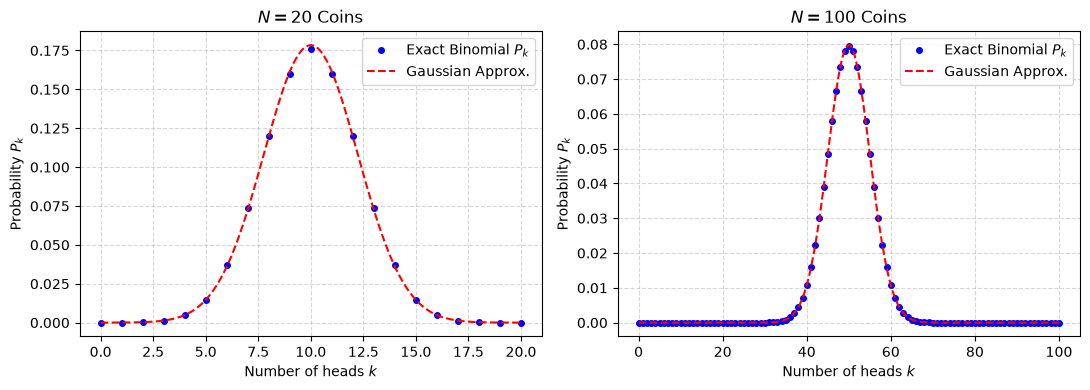

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, N in zip(axes, [20, 100]):
    k, _, p_exact = get_distribution(N)

    # Gaussian approximation: mu = N/2, sigma = sqrt(N)/2
    mu = N / 2.0
    sigma = np.sqrt(N) / 2.0
    k_cont = np.linspace(0, N, 300)
    p_gauss = (1.0 / np.sqrt(2 * np.pi * sigma**2)) * np.exp(-((k_cont - mu) ** 2) / (2 * sigma**2))

    ax.plot(k, p_exact, "bo", markersize=4, label="Exact Binomial $P_k$")
    ax.plot(k_cont, p_gauss, "r--", lw=1.5, label="Gaussian Approx.")
    ax.set_title(f"$N = {N}$ Coins")
    ax.set_xlabel("Number of heads $k$")
    ax.set_ylabel("Probability $P_k$")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()

plt.tight_layout()
plt.show()